# Did crime in LA really fall?

The working behind the [findings report](../findings/README.md), using about a million crime reports from the City of Los Angeles.

The calculations live in [`findings/analysis.py`](../findings/analysis.py) and the charts in [`findings/charts.py`](../findings/charts.py), so this notebook, the report and the tests all share the same code. The full download isn't in the repo: [`data/prepare.py`](../data/prepare.py) turns it into the small files used here.

In [1]:
import sys
from pathlib import Path

import pandas as pd

ROOT = Path.cwd() if (Path.cwd() / "findings").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "findings"))

import analysis as an
import charts

## 1. Check when the data stops being comparable

Monthly totals fall off a cliff in 2024. LAPD moved to a new records system on 7 March 2024 and has since retired this dataset, so this can't be read as a fall in crime.

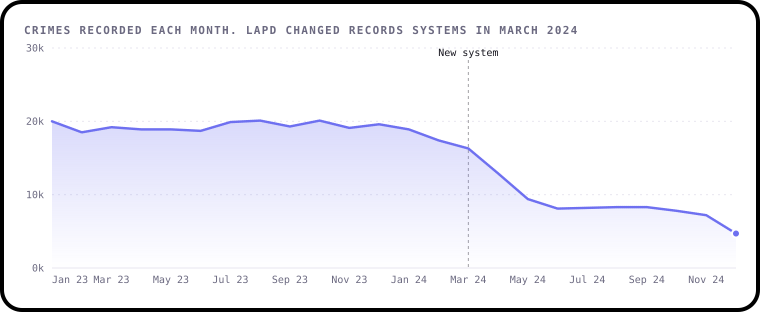

In [2]:
charts.the_cliff()

In [3]:
pd.Series(an.the_cliff()).round(2)

february        17394.00
december         4697.00
drop                0.73
average_2023    19362.08
dtype: float64

## 2. Check what cleaning removes before removing it

Dropping every row with a blank field looks harmless at 15% of rows, but the blanks aren't random. Stolen vehicle reports have no victim details.

In [4]:
an.cleaning_damage().head(6).round(3)

,all,kept,lost,rank_all,rank_kept
crime,,,,,
VEHICLE - STOLEN,115184,546,0.995,1,66
BATTERY - SIMPLE ASSAULT,74821,74694,0.002,2,1
BURGLARY FROM VEHICLE,63515,63415,0.002,3,2
THEFT OF IDENTITY,62536,60343,0.035,4,4
"VANDALISM - FELONY ($400 & OVER, ALL CHURCH VANDALISMS)",61086,60975,0.002,5,3
BURGLARY,57871,57377,0.009,6,5


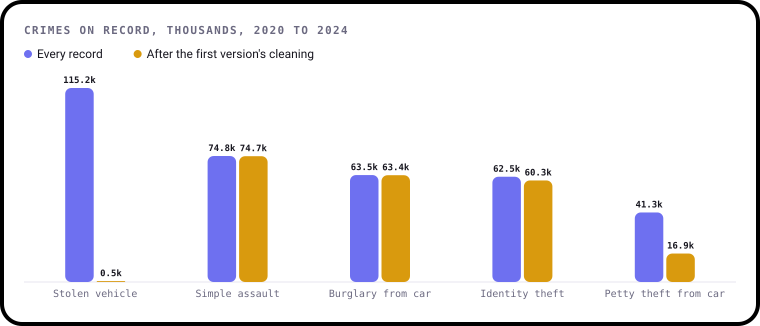

In [5]:
charts.cleaning_damage()

From here on, those rows stay in, and everything stops before the switch.

## 3. The reliable years

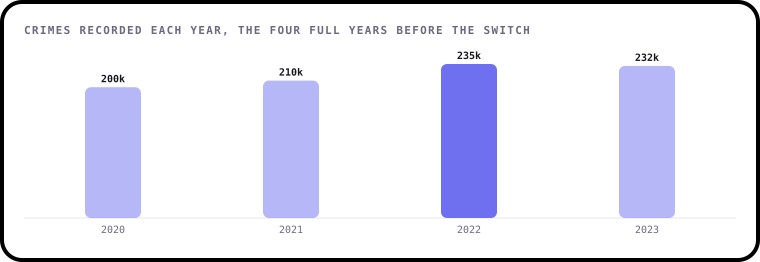

In [6]:
charts.yearly()

In [7]:
an.change_by_crime().round(1).rename(index=an.NAMES).to_frame("% change, 2020 to 2023")

,"% change, 2020 to 2023"
crime,
Identity theft,50.6
Stolen vehicle,17.8
Simple assault,15.3
Burglary,11.3
Aggravated assault,10.1
Burglary from vehicle,6.7
Petty theft,5.6
Felony vandalism,1.9
Partner assault,0.1


## 4. Which crimes, and where

Area figures are counts and not rates, as the data has no population figures.

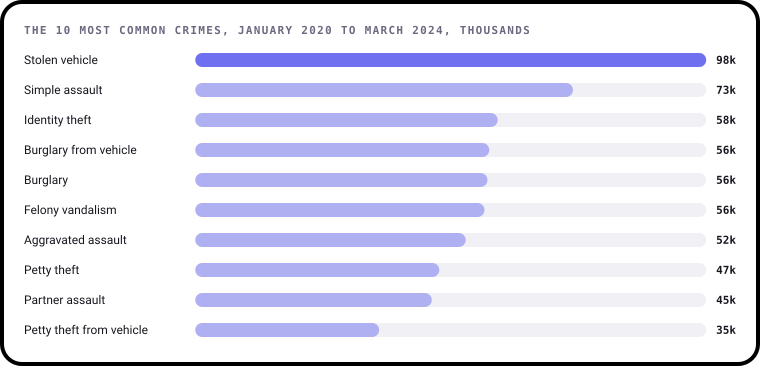

In [8]:
charts.top_crimes()

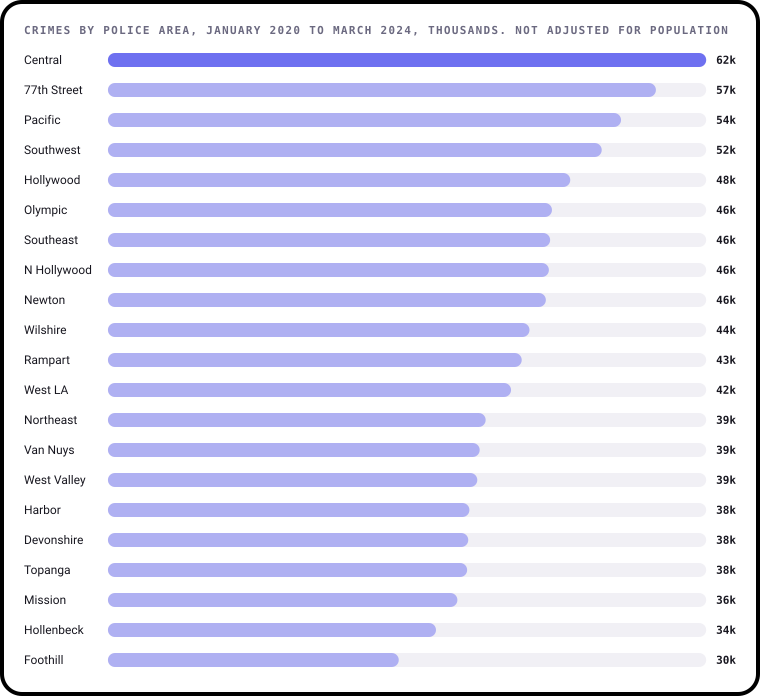

In [9]:
charts.by_area()

## 5. When, and how much of "when" is an estimate

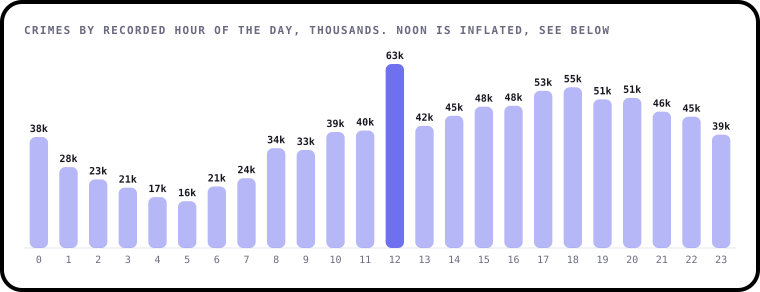

In [10]:
charts.by_hour()

In [11]:
pd.Series(an.time_quality()).round(3)

on_the_hour         0.393
first_of_month      0.460
identity_at_noon    0.170
identity_late       0.289
dtype: float64

In [12]:
an.by_day_of_week().to_frame("crimes")

,crimes
dow,
Monday,129596
Tuesday,126175
Wednesday,130647
Thursday,129008
Friday,140102
Saturday,134331
Sunday,127597


## 6. Arrests

This status may not be updated after a report is filed, so treat these as a minimum and not an official clearance rate.

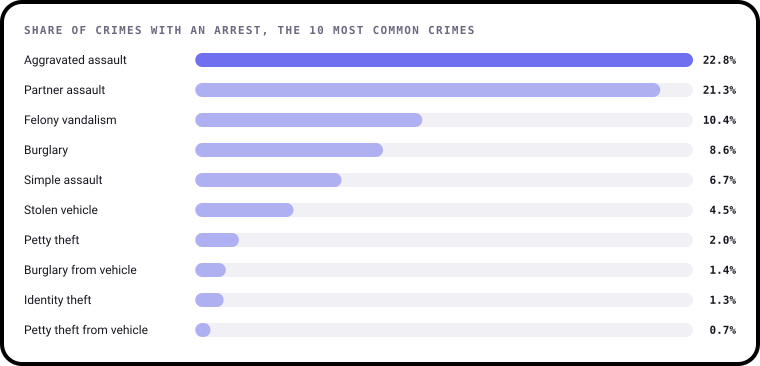

In [13]:
charts.arrests()

In [14]:
pd.Series(an.overall_outcomes()).round(3)

arrest    0.094
open      0.788
dtype: float64

## 7. Can the type of crime be predicted?

Train on 2020 to 2022 and test on 2023. The first version never compared its 10% accuracy with simply guessing the most common crime, which is the first thing to check.

In [15]:
result = an.models()
print(f"Train on {result['train_size']:,} crimes, test on {result['test_size']:,}")
(result["accuracy"] * 100).round(1).to_frame("% correct")

Train on 140,730 crimes, test on 50,455


,% correct
Always guess the most common,10.6
When only,12.1
When and police area,12.9
"When, area and type of place",28.2


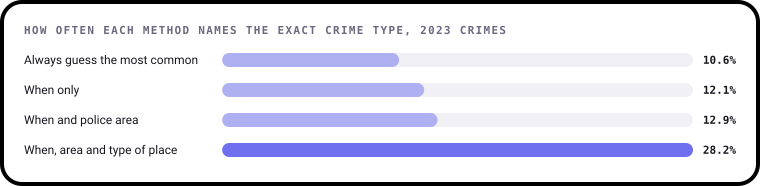

In [16]:
charts.model_scores()

Time adds very little, and the type of place adds a lot. This isn't a tool for policing decisions, since recorded crime reflects where crimes get reported and policed as well as where they happen.

## Limits

- This data can't show whether crime rose or fell after March 2024.
- Many crimes are never reported, and reporting differs between crimes and neighbourhoods.
- There are no population figures, so these counts aren't rates.
- The data shows patterns, not causes.